# 01 — Data audit

Audit of the cleaned UTS co-authorship dataset built by `linkpred.data.build`.
All tables come from `linkpred.data.audit`, which also writes them to `report/data_audit/`
and regenerates the numeric part of `docs/data_audit.md`. The audit is descriptive and uses
all years; nothing here is used as a model input.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import pandas as pd
from IPython.display import Image, display
from linkpred.config import load_config
from linkpred.data import audit

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.3f}".format)
cfg = load_config()
res = audit.run(cfg)
log = json.loads(Path("report/data_audit/cleaning_log.json").read_text())

## Cleaning log
Every cleaning rule and how many rows it touched.

In [2]:
pd.Series(log).to_frame("value")

,value
source,/Users/zareenshyma/Documents/uts-research-inte...
raw_works,63514
raw_authorships,356586
duplicate_work_ids,0
missing_year_dropped,0
out_of_year_range_dropped,0
excluded_type_dropped,658
excluded_type_counts,"{'erratum': 283, 'paratext': 242, 'peer-review..."
duplicate_doi,7
duplicate_title_year,1356


## Works, authors and new links per year

In [3]:
res["yearly"]

,year,works,works_over_cap,share_over_cap,share_with_abstract,authorships,active_authors,active_uts_authors,new_authors,edge_rows,distinct_pairs,new_pairs,new_pairs_uts_uts
0,2015,3374,8,0.002,0.639,13853,7722,2163,7722,32394,26063,26063,3707
1,2016,3933,9,0.002,0.649,16900,9450,2491,6739,43381,35490,30478,3497
2,2017,4404,17,0.004,0.673,19864,11284,2744,7446,49836,40465,32915,3365
3,2018,5351,27,0.005,0.642,24863,13793,3033,8770,64055,52056,41505,3878
4,2019,6210,35,0.006,0.618,29751,16175,3385,9695,81291,64826,50685,4809
5,2020,6652,62,0.009,0.660,35952,19727,3669,11823,105908,84284,66444,5518
6,2021,6773,74,0.011,0.659,37890,20839,3722,11699,112676,89861,67475,5268
7,2022,6231,73,0.012,0.681,37504,21166,3767,11771,120031,96498,73460,5661
8,2023,6245,56,0.009,0.681,37624,21629,3775,11942,120516,96731,73930,5882
9,2024,6105,53,0.009,0.738,36701,22007,3876,12057,117074,97054,73351,6051


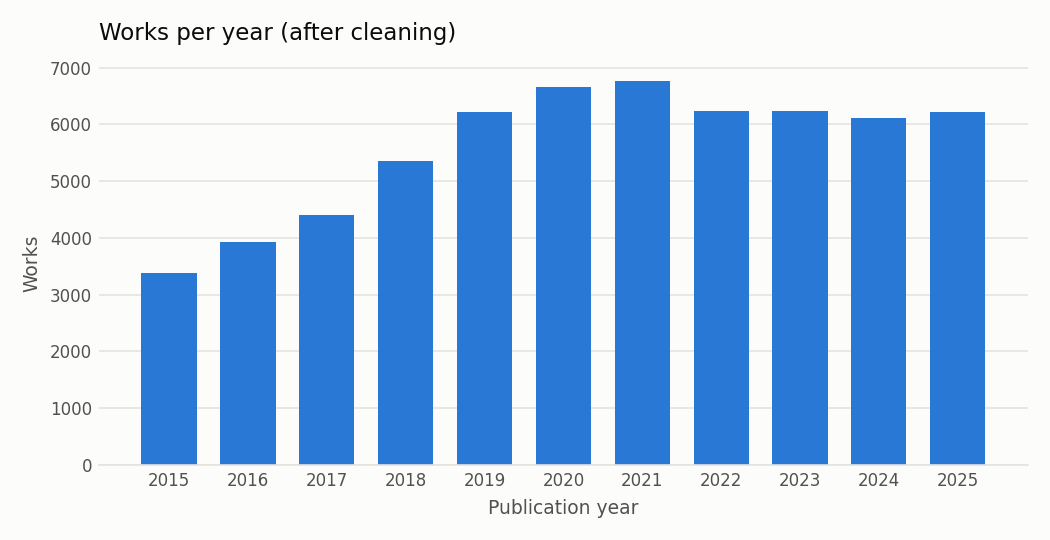

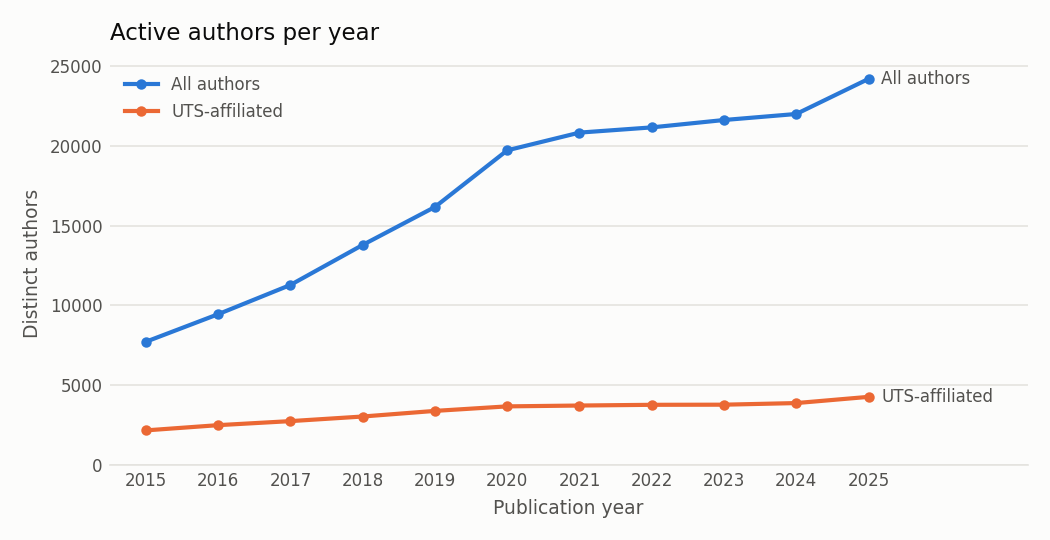

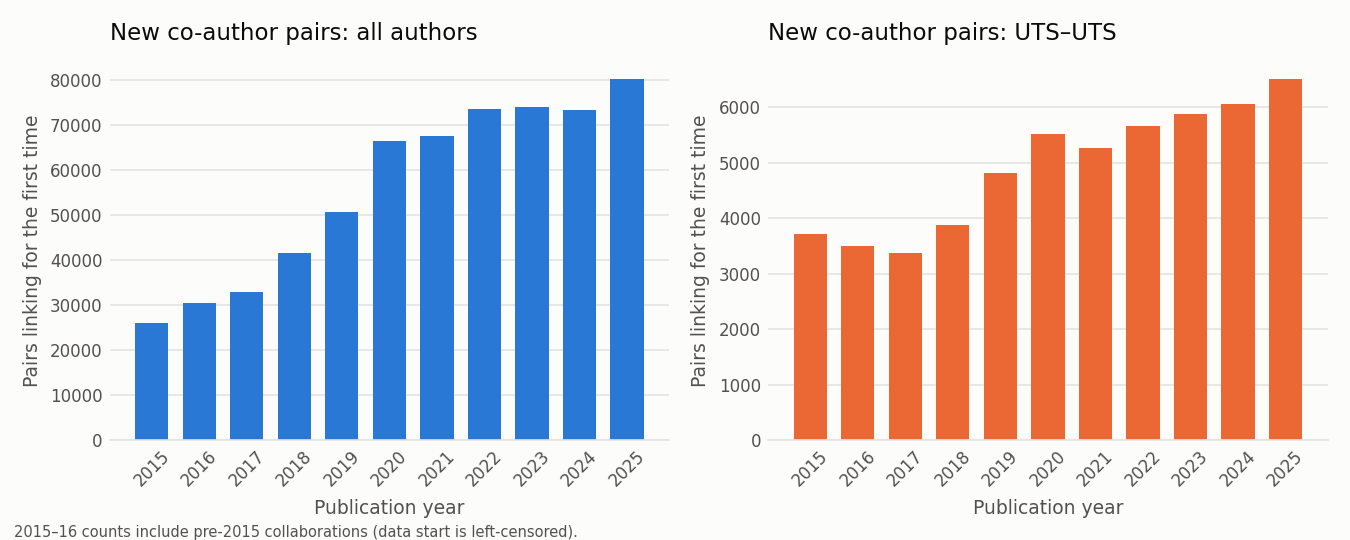

In [4]:
for f in ["audit_works_per_year.png", "audit_authors_per_year.png", "audit_new_edges_per_year.png"]:
    display(Image(f"figures/{f}"))

Note: 2015–2016 "new" pairs are inflated because the snapshot starts in 2015, so
collaborations that began earlier look new. This is one reason early years make poor label windows.

## Author cap
Works with more than `max_authors_per_work` authors are kept in `works.parquet` but produce no edges.

505 of 61493 works (0.82%) exceed 25 authors; 698,260 would-be edge rows not created (lower bound: API caps authorships at 100).


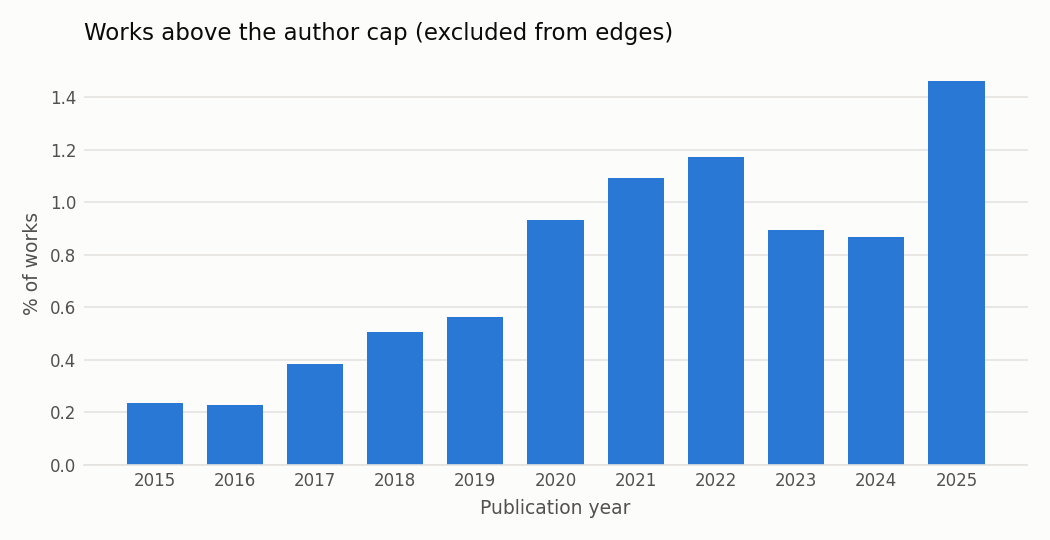

n_authors,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
works,5477,6578,9113,9940,8568,6526,4196,2798,2092,1455,1002,736,570,417,313,267,217,170,101,113,104,77,62,49,47,50,35,22,16,382


In [5]:
w = pd.read_parquet("data/processed/works.parquet", columns=["work_id", "year", "n_authors", "type"])
cap = cfg["data"]["max_authors_per_work"]
print(f"{(w.n_authors > cap).sum()} of {len(w)} works ({(w.n_authors > cap).mean():.2%}) exceed {cap} authors; "
      f"{log['hyper_would_be_edges']:,} would-be edge rows not created (lower bound: API caps authorships at 100).")
display(Image("figures/audit_share_over_cap.png"))
w.n_authors.clip(upper=30).value_counts().sort_index().rename("works").to_frame().T

## Degree distribution (all years)

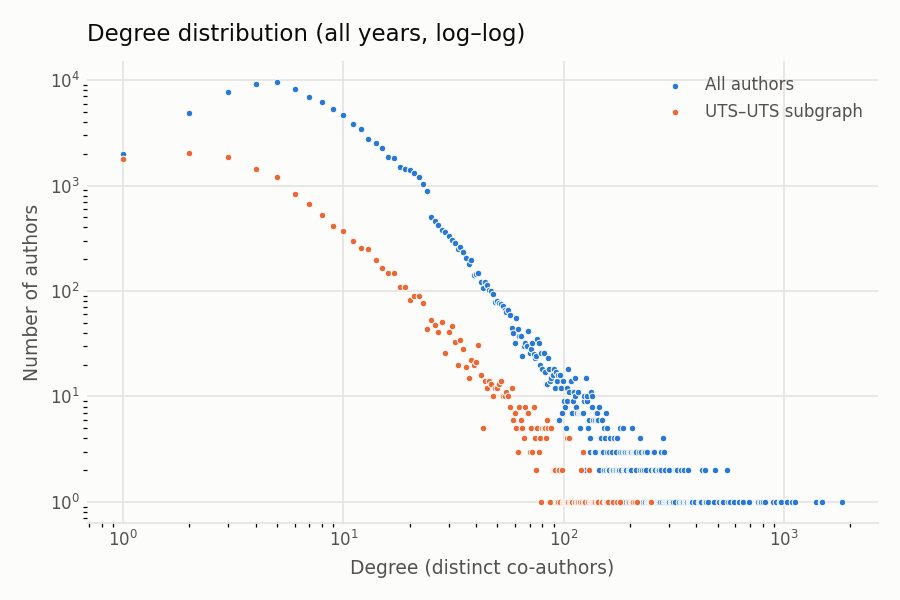

,nodes,edges,components,giant_component_share,mean_degree,median_degree,max_degree,density
all,100121.000,616387.000,1046.000,0.949,12.313,8.000,1825.000,0.000
uts_uts,14150.000,61567.000,339.000,0.930,8.702,4.000,250.000,0.001


In [6]:
display(Image("figures/audit_degree_loglog.png"))
pd.DataFrame(res["graph"]).T

Heavy-tailed, as expected for co-authorship. The highest-degree authors are prolific UTS
researchers; several carry a disambiguation flag, so some hubs may be merged profiles.

In [7]:
e = pd.read_parquet("data/processed/edges.parquet").drop_duplicates(["author_u", "author_v"])
a = pd.read_parquet("data/processed/authors.parquet").set_index("author_id")
deg = pd.concat([e.author_u, e.author_v]).value_counts().head(10).rename("degree")
a.loc[deg.index, ["n_works", "n_uts_works", "first_year", "last_year", "disambiguation_flag"]].join(deg)

,n_works,n_uts_works,first_year,last_year,disambiguation_flag,degree
A5040015789,741,735,2017,2025,True,1825
A5076048446,420,378,2015,2025,False,1493
A5056472365,635,632,2015,2025,True,1467
A5007273016,516,516,2015,2025,False,1391
A5035358791,419,255,2018,2025,True,1125
A5059040421,598,595,2017,2025,True,1084
A5005228053,525,524,2017,2025,True,1035
A5073251236,404,2,2017,2025,False,973
A5074742233,350,317,2015,2025,True,960
A5039341855,516,515,2018,2025,True,954


## Missingness

In [8]:
res["missingness"]

,level,field,n_missing,n_total,handling,share_missing
0,work,publication_year,0,63514,dropped,0.000
1,work,doi,2035,61493,kept; title+year dedup only,0.033
2,work,title (empty),51,61493,kept,0.001
3,work,abstract,19950,61493,kept; has_abstract=False,0.324
4,authorship,author_id,10123,338522,dropped,0.030
5,authorship,institution_ids (empty),9514,328399,kept,0.029
6,work,no UTS-affiliated identified author,1346,61493,kept,0.022


## Duplicates and disambiguation

In [9]:
flags = pd.read_parquet("data/processed/disambiguation_flags.parquet")
print("duplicates removed: DOI =", log["duplicate_doi"], "| title+year =", log["duplicate_title_year"])
print("disambiguation groups (all / UTS):", log["disambig_groups"], "/", log["disambig_groups_uts"])
print("author IDs involved (all / UTS):", log["disambig_author_ids"], "/", log["disambig_author_ids_uts"])
flags["n_ids"].value_counts().sort_index().rename("groups").to_frame().T

duplicates removed: DOI = 7 | title+year = 1356
disambiguation groups (all / UTS): 5550 / 1011
author IDs involved (all / UTS): 8961 / 2689


n_ids,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,26
groups,4402,624,284,83,43,21,11,8,4,2,8,3,4,46,3,1,1,1,1


## Work types
All types are kept for now (see open questions in `docs/data_audit.md`).

In [10]:
pd.read_csv("report/data_audit/work_types.csv").set_index("type").T

type,article,conference-paper,book-chapter,preprint,other,review,conference-abstract,reference-entry,editorial,book,dataset,book-review,report,letter,data-paper,retraction,supplementary-materials,dissertation,software,software-paper
works,41617,7646,3587,2617,2151,1035,597,571,567,424,295,172,75,49,37,20,13,10,6,4


## Split candidates

For each cutoff `c` and window `[c, window_end]`: positives are pairs first co-authoring in the
window whose two authors are both already in the graph (edges with year < c). `pos_uts_uts` also
requires both to have had a UTS affiliation before `c`. This is the table the cutoff
recommendation in `docs/decisions.md` is based on.

In [11]:
res["candidates"]

,cutoff,window_end,window_years,graph_nodes,graph_edges_distinct,uts_nodes,new_pairs_in_window,pos_both_seen,pos_uts_uts,pos_uts_any_both_seen,share_both_seen
0,2017,2017,1,13398,56541,3265,32915,2994,1044,2249,0.091
1,2017,2018,2,13398,56541,3265,74420,5457,1934,4123,0.073
2,2017,2019,3,13398,56541,3265,125105,7319,2605,5562,0.059
3,2018,2018,1,19996,89456,4457,41505,4285,1396,3139,0.103
4,2018,2019,2,19996,89456,4457,92190,7657,2536,5660,0.083
5,2018,2020,3,19996,89456,4457,158634,10559,3412,7793,0.067
6,2019,2019,1,27888,130961,5682,50685,5948,1775,4263,0.117
7,2019,2020,2,27888,130961,5682,117129,11033,3255,7849,0.094
8,2019,2021,3,27888,130961,5682,184604,14958,4418,10667,0.081
9,2020,2020,1,36569,181646,6967,66444,8044,2197,5466,0.121


In [12]:
c = res["candidates"]
c[c.window_years == 1][["cutoff", "graph_nodes", "uts_nodes", "new_pairs_in_window", "pos_both_seen", "share_both_seen", "pos_uts_any_both_seen", "pos_uts_uts"]]

,cutoff,graph_nodes,uts_nodes,new_pairs_in_window,pos_both_seen,share_both_seen,pos_uts_any_both_seen,pos_uts_uts
0,2017,13398,3265,32915,2994,0.091,2249,1044
3,2018,19996,4457,41505,4285,0.103,3139,1396
6,2019,27888,5682,50685,5948,0.117,4263,1775
9,2020,36569,6967,66444,8044,0.121,5466,2197
12,2021,46845,8325,67475,9769,0.145,6129,2290
15,2022,56895,9600,73460,10482,0.143,6719,2364
18,2023,67287,10962,73930,10845,0.147,6471,2244
21,2024,77933,12376,73351,10881,0.148,6757,2216
23,2025,88562,13829,80081,11717,0.146,7228,2533
